In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MaxNLocator

tune = "../artifacts/eval/eval_results_checkpoint_epochbest_20260918-140740.pt"
tune_reverse = "../artifacts/eval/eval_results_checkpoint_epochbest_20260918-140805.pt"
upper = "../artifacts/eval/eval_results_checkpoint_epochbest_20260918-140723.pt"
upper_reverse = "../artifacts/eval/eval_results_checkpoint_epochbest_20260918-140829.pt"
baseline = "../artifacts/eval/eval_results_checkpoint_epochbest_20260918-081326.pt"
vae = "../artifacts/eval/eval_results_checkpoint_epochbest_20260919-213140.pt"

def get_json(path):
    with open(path, "r") as f:
        return json.load(f)

In [2]:
data_tune = get_json(tune)
data_tune_reverse = get_json(tune_reverse)
data_upper = get_json(upper)
data_upper_reverse = get_json(upper_reverse)
data_baseline = get_json(baseline)
data_vae = get_json(vae)

print(np.max([np.max(i) for i in data_baseline["losses_position"]]))

"""
datasets = [
    data_tune,
    data_tune_reverse,
    data_upper,
    data_upper_reverse,
    data_baseline,
]

for data in datasets:
    losses = data["losses_position"]

    # Find the entry with the largest maximum loss
    worst_idx = np.argmax([np.max(i) for i in losses])

    # Remove it
    data["losses_position"].pop(worst_idx)
print(np.max([np.max(i) for i in data_baseline["losses_position"]]))
"""


317.3498229980469


'\ndatasets = [\n    data_tune,\n    data_tune_reverse,\n    data_upper,\n    data_upper_reverse,\n    data_baseline,\n]\n\nfor data in datasets:\n    losses = data["losses_position"]\n\n    # Find the entry with the largest maximum loss\n    worst_idx = np.argmax([np.max(i) for i in losses])\n\n    # Remove it\n    data["losses_position"].pop(worst_idx)\nprint(np.max([np.max(i) for i in data_baseline["losses_position"]]))\n'

In [3]:
def object_to_dataframe(data, rnn=False):
    to_return = {}
    to_return["x"] = data["x"]
    to_return["mean"] = data["mean"]
    to_return["logvar"] = data["logvar"]
    to_return["losses"] = data["losses"]    
    to_return["losses_position"] = data["losses_position"]
    to_return["mse_losses"] = data["mse_losses"]
    to_return["mse_losses_position"] = data["mse_losses_position"]

    to_return["mse_loss"] = data["mse_loss"]
    #to_return["losses"] = data["losses"]
    for key in ["losses_position", "mse_losses_position"]:
        for sublist in data[key]:
            sublist[13] = sublist[12]*0.5 + sublist[14]*0.5
    for k in list(to_return.keys()):
        try:
            print("Key: ", k , " Len: ", len(to_return[k]))
        except:
            print("did not work for" , k)


    


    return pd.DataFrame.from_dict(to_return)


In [4]:
df_tune = object_to_dataframe(data_tune)
df_tune_reverse = object_to_dataframe(data_tune_reverse)

df_upper = object_to_dataframe(data_upper)
df_upper_reverse = object_to_dataframe(data_upper_reverse)

df_baseline = object_to_dataframe(data_baseline, rnn=True)

df_vae = object_to_dataframe(data_vae)


Key:  x  Len:  5264
Key:  mean  Len:  5264
Key:  logvar  Len:  5264
Key:  losses  Len:  5264
Key:  losses_position  Len:  5264
Key:  mse_losses  Len:  5264
Key:  mse_losses_position  Len:  5264
did not work for mse_loss
Key:  x  Len:  5264
Key:  mean  Len:  5264
Key:  logvar  Len:  5264
Key:  losses  Len:  5264
Key:  losses_position  Len:  5264
Key:  mse_losses  Len:  5264
Key:  mse_losses_position  Len:  5264
did not work for mse_loss
Key:  x  Len:  5264
Key:  mean  Len:  5264
Key:  logvar  Len:  5264
Key:  losses  Len:  5264
Key:  losses_position  Len:  5264
Key:  mse_losses  Len:  5264
Key:  mse_losses_position  Len:  5264
did not work for mse_loss
Key:  x  Len:  5264
Key:  mean  Len:  5264
Key:  logvar  Len:  5264
Key:  losses  Len:  5264
Key:  losses_position  Len:  5264
Key:  mse_losses  Len:  5264
Key:  mse_losses_position  Len:  5264
did not work for mse_loss
Key:  x  Len:  5264
Key:  mean  Len:  5264
Key:  logvar  Len:  5264
Key:  losses  Len:  5264
Key:  losses_position  Len:

MSE ERRORS PER POSITION: 
NLL ERRORS PER POSITION: 
MSE ERRORS PER POSITION: 
NLL ERRORS PER POSITION: 


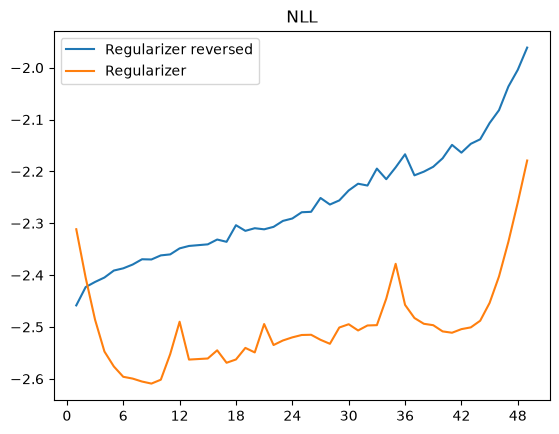

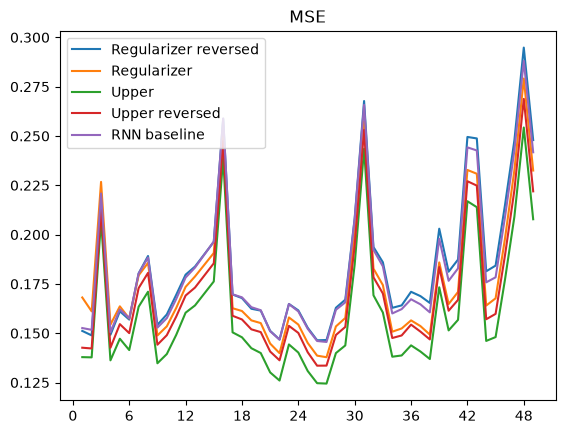

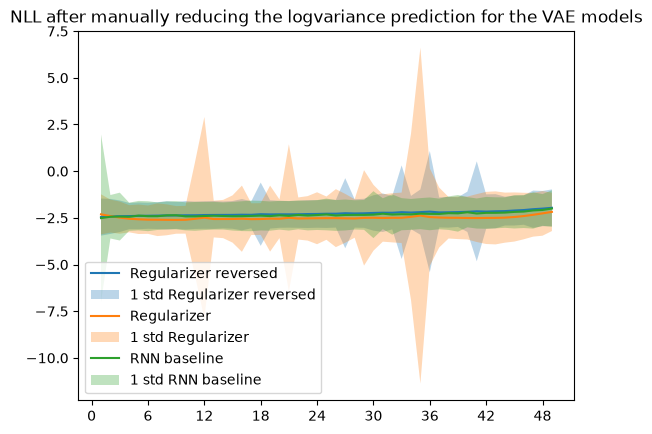

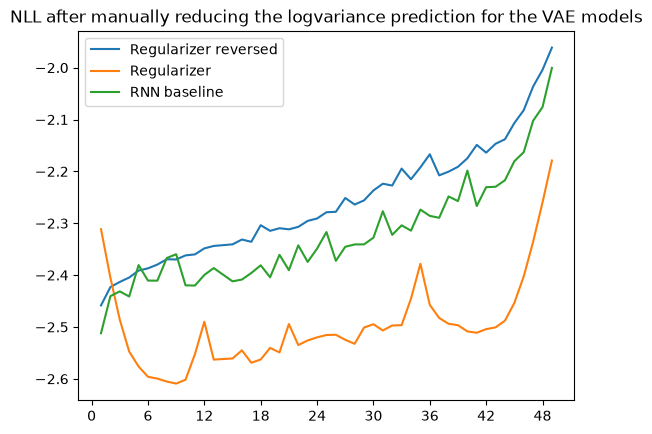

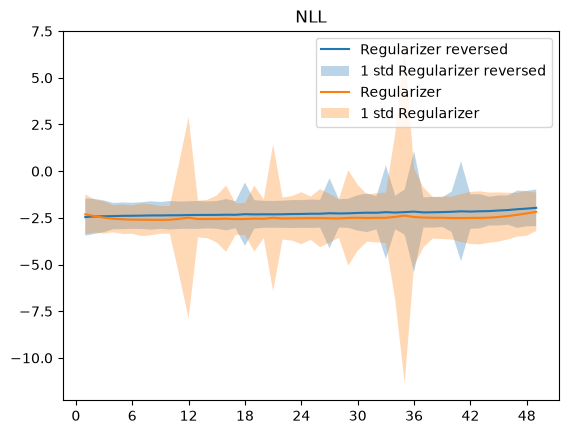

In [5]:

import numpy as np
import matplotlib.pyplot as plt


def get_horizon_error(*datasets, title="", labels=None):


    if labels is None:
        labels = [f"Dataset {i + 1}" for i in range(len(datasets))]

    if len(labels) != len(datasets):
        raise ValueError("Number of labels must match number of datasets.")

    fig, ax = plt.subplots()

    for dataset, label in zip(datasets, labels):
        errors_array = np.stack(dataset)
        mean = np.mean(errors_array, axis=0)

        # Match the original behaviour
        x = np.arange(1, len(mean))
        ax.plot(x, mean[:len(x)], label=label)

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_title(title)
    ax.legend()

    return fig, ax


def get_horizon_error_std(*datasets, title="", labels=None):


    if labels is None:
        labels = [f"Dataset {i + 1}" for i in range(len(datasets))]

    if len(labels) != len(datasets):
        raise ValueError("Number of labels must match number of datasets.")

    fig, ax = plt.subplots()

    for dataset, label in zip(datasets, labels):
        errors_array = np.stack(dataset)

        mean = np.mean(errors_array, axis=0)
        std = np.std(errors_array, axis=0)

        lower = mean - std
        upper = mean + std

        x = np.arange(1, len(mean))

        ax.plot(
            x,
            mean[:len(x)],
            label=label
        )

        ax.fill_between(
            x,
            lower[:len(x)],
            upper[:len(x)],
            alpha=0.3,
            label=f"1 std {label}"
        )

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_title(title)
    ax.legend()

    return fig, ax


print("MSE ERRORS PER POSITION: ")
#get_horizon_error(df_new["mse_losses_position"], df_old["mse_losses_position"], title="MSE")
print("NLL ERRORS PER POSITION: ")

#get_horizon_error(df_tune_long["losses_position"],df_baseline_long["losses_position"], title="NLL", labels=["Regularizer", "Baseline"])


get_horizon_error(df_tune_reverse["losses_position"],df_tune["losses_position"], title="NLL", labels=["Regularizer reversed", "Regularizer"])

get_horizon_error(df_tune_reverse["mse_losses_position"],
                  df_tune["mse_losses_position"],
                  df_upper["mse_losses_position"],
                  df_upper_reverse["mse_losses_position"],
                  df_baseline["mse_losses_position"],
                  title="MSE",
                  labels=[
                      "Regularizer reversed",
                      "Regularizer",
                      "Upper",
                      "Upper reversed",
                      "RNN baseline"
                  ])



get_horizon_error_std(df_tune_reverse["losses_position"],df_tune["losses_position"], df_baseline["losses_position"], title="NLL after manually reducing the logvariance prediction for the VAE models", labels=["Regularizer reversed", "Regularizer", "RNN baseline"])

get_horizon_error(df_tune_reverse["losses_position"],df_tune["losses_position"], df_baseline["losses_position"], title="NLL after manually reducing the logvariance prediction for the VAE models", labels=["Regularizer reversed", "Regularizer", "RNN baseline"])


get_horizon_error_std(df_tune_reverse["losses_position"],
                      df_tune["losses_position"],
                      #df_baseline["losses_position"],
                      title="NLL",
                      labels=[
                          "Regularizer reversed",
                          "Regularizer",
                          #"RNN baseline"
                      ]
                     )


print("MSE ERRORS PER POSITION: ")
#get_horizon_error_std(df_new["mse_losses_position"], df_old["mse_losses_position"], df_rnn["mse_losses_position"], title="MSE")
print("NLL ERRORS PER POSITION: ")
#get_horizon_error_std(df_new["losses_position"],df_old["losses_position"], df_rnn["losses_position"], title="NLL")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


import numpy as np
import matplotlib.pyplot as plt


def plot_horizon_metric(*datasets, labels=None, title="title"):

    if len(datasets) == 0:
        raise ValueError("At least one dataset must be provided.")

    if labels is None:
        labels = [f"Dataset {i + 1}" for i in range(len(datasets))]

    if len(labels) != len(datasets):
        raise ValueError("Number of labels must match number of datasets.")

    fig, ax = plt.subplots(figsize=(8, 6))

    for dataset, label in zip(datasets, labels):
        errors = np.stack(dataset)

        mean = np.mean(errors, axis=0)
        std = np.std(errors, axis=0, ddof=1)
        n = errors.shape[0]

        # 95% confidence interval
        ci = 1.96 * std / np.sqrt(n)

        x = np.arange(1, len(mean))

        ax.plot(
            x,
            mean[:len(x)],
            lw=2,
            label=label
        )

        ax.fill_between(
            x,
            mean[:len(x)] - ci[:len(x)],
            mean[:len(x)] + ci[:len(x)],
            alpha=0.25,
            label=f"95% CI {label}"
        )
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlabel("Forecast horizon")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

    return fig, ax

plot_horizon_metric(df_tune_reverse["losses_position"],
                    df_tune["losses_position"],
                    df_upper_reverse["losses_position"],
                    df_upper["losses_position"],
                    df_baseline["losses_position"],
                    title="NLL",
                    labels=[
                        "Regularizer reversed",
                        "Regularizer",
                        "Upper bounded reversed",
                        "Upper bounded",
                        "RNN baseline"
                    ])
plot_horizon_metric(df_tune_reverse["mse_losses_position"],
                    df_tune["mse_losses_position"],
                    df_upper_reverse["mse_losses_position"],
                    df_upper["mse_losses_position"],
                    df_baseline["mse_losses_position"],
                    title="MSE",
                    labels=[
                        "Regularizer reversed",
                        "Regularizer",
                        "Upper bounded reversed",
                        "Upper bounded",
                        "RNN baseline"
                    ])


plot_horizon_metric(df_tune_reverse["losses_position"],
                    df_tune["losses_position"],
                    df_baseline["losses_position"],
                    df_vae["losses_position"],
                    title="NLL",
                    labels=[
                        "Regularizer reversed",
                        "Regularizer",
                        "RNN baseline",
                        "VAE baseline",
                    ])

plot_horizon_metric(df_tune_reverse["mse_losses_position"],
                    df_tune["mse_losses_position"],
                    df_baseline["mse_losses_position"],
                    title="MSE",
                    labels=[
                        "Regularizer reversed",
                        "Regularizer",
                        "RNN baseline"
                    ])

"""
print("MSE")
plot_horizon_metric(
    df_reg["mse_losses_position"],
    df_upper["mse_losses_position"],
    title="MSE"
)
print("NLL")
plot_horizon_metric(
    df_reg["losses_position"],
    df_upper["losses_position"],
    title="NLL"
)


print("MSE")
plot_horizon_metric(
    df_reg["mse_losses_position"],
    df_upper["mse_losses_position"],
   df_baseline["mse_losses_position"],
    title="MSE"
)

print("NLL")
plot_horizon_metric(
    df_reg["losses_position"],
    df_upper["losses_position"],
    df_baseline["losses_position"],
    title="NLL"
)
"""

In [ ]:
def plot_difference(new, old, title):
    errors_new = np.stack(new)
    errors_old = np.stack(old)

    diff = errors_new - errors_old

    mean_diff = np.mean(diff, axis=0)
    std_diff = np.std(diff, axis=0, ddof=1)

    ci = 1.96 * std_diff / np.sqrt(diff.shape[0])

    x = np.arange(1, len(mean_diff) + 1)

    fig, ax = plt.subplots(figsize=(8, 4))

    ax.axhline(0, color="black", linestyle="--", alpha=0.7)

    ax.plot(x, mean_diff, lw=2, color="tab:green")

    ax.fill_between(
        x,
        mean_diff - ci,
        mean_diff + ci,
        alpha=0.25,
        color="tab:green"
    )

    ax.set_xlabel("Forecast horizon")
    ax.set_ylabel("New − Old")
    ax.set_title(title)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


print("MSE")
plot_difference(
    df_new["mse_losses_position"],
    df_old["mse_losses_position"],
    "MSE"
)

print("NLL")
plot_difference(
    df_new["losses_position"],
    df_old["losses_position"],
    "NLL"
)